Importing Libaries 

In [1]:
from pathlib import Path
import requests

In [2]:
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

In [3]:
pdb_id = "1NL9"

url = f"https://files.rcsb.org/download/{pdb_id}.pdb"

response = requests.get(url, timeout=30)
response.raise_for_status()

In [4]:
# Save the protein structure

file_path = data_dir / f"{pdb_id}.pdb"

file_path.write_bytes(response.content)

print("Protein downloaded successfully!")
print("Saved to:", file_path)

Protein downloaded successfully!
Saved to: /Users/tavimangoma/PCOS_Drug_Repurposing/data/1NL9.pdb


Import Biopython and load the protein

In [5]:
from Bio.PDB import PDBParser

# Create a protein structure parser
parser = PDBParser(QUIET=True)

# Load the PTP1B structure we downloaded
structure = parser.get_structure("PTP1B", str(file_path))

print("Protein structure loaded successfully!")

Protein structure loaded successfully!


In [6]:
# Examine the chains in the structure

for model in structure:
    for chain in model:
        print("Chain ID:", chain.id)
        print("Number of residues:", len(list(chain.get_residues())))

Chain ID: A
Number of residues: 569


In [7]:
# Identify non-protein residues in the structure

for residue in structure.get_residues():
    if residue.id[0] != " ":
        print(
            "Residue:", residue.resname,
            "| Chain:", residue.get_parent().id,
            "| Residue number:", residue.id[1]
        )

Residue: 989 | Chain: A | Residue number: 322
Residue: HOH | Chain: A | Residue number: 401
Residue: HOH | Chain: A | Residue number: 402
Residue: HOH | Chain: A | Residue number: 403
Residue: HOH | Chain: A | Residue number: 404
Residue: HOH | Chain: A | Residue number: 405
Residue: HOH | Chain: A | Residue number: 406
Residue: HOH | Chain: A | Residue number: 407
Residue: HOH | Chain: A | Residue number: 408
Residue: HOH | Chain: A | Residue number: 409
Residue: HOH | Chain: A | Residue number: 410
Residue: HOH | Chain: A | Residue number: 411
Residue: HOH | Chain: A | Residue number: 412
Residue: HOH | Chain: A | Residue number: 413
Residue: HOH | Chain: A | Residue number: 414
Residue: HOH | Chain: A | Residue number: 415
Residue: HOH | Chain: A | Residue number: 416
Residue: HOH | Chain: A | Residue number: 417
Residue: HOH | Chain: A | Residue number: 418
Residue: HOH | Chain: A | Residue number: 419
Residue: HOH | Chain: A | Residue number: 420
Residue: HOH | Chain: A | Residue 

In [8]:
import numpy as np

# Find the known inhibitor
ligand_atoms = []

for residue in structure.get_residues():
    if residue.resname == "989":
        ligand_atoms.extend(
            atom.coord for atom in residue.get_atoms()
        )

if ligand_atoms:
    ligand_center = np.mean(ligand_atoms, axis=0)

    print("Inhibitor 989 found!")
    print("Binding-site reference center (Å):")
    print("X:", round(float(ligand_center[0]), 2))
    print("Y:", round(float(ligand_center[1]), 2))
    print("Z:", round(float(ligand_center[2]), 2))
else:
    print("Inhibitor 989 was not found.")

Inhibitor 989 found!
Binding-site reference center (Å):
X: 33.68
Y: 28.42
Z: 20.58


Prepare the protein for molecular docking

In [9]:
from Bio.PDB import PDBIO, Select, is_aa

# Select only protein amino acids
class ProteinSelect(Select):
    def accept_residue(self, residue):
        return is_aa(residue, standard=True)

# Select only inhibitor 989
class LigandSelect(Select):
    def accept_residue(self, residue):
        return residue.resname == "989"

# Create PDB file writer
io = PDBIO()
io.set_structure(structure)

# Save clean protein
protein_path = data_dir / "PTP1B_clean.pdb"
io.save(str(protein_path), ProteinSelect())

# Save inhibitor
ligand_path = data_dir / "PTP1B_inhibitor_989.pdb"
io.save(str(ligand_path), LigandSelect())

print("Protein and inhibitor separated!")
print("Protein:", protein_path)
print("Inhibitor:", ligand_path)

Protein and inhibitor separated!
Protein: /Users/tavimangoma/PCOS_Drug_Repurposing/data/PTP1B_clean.pdb
Inhibitor: /Users/tavimangoma/PCOS_Drug_Repurposing/data/PTP1B_inhibitor_989.pdb


In [10]:
# Verify protein and inhibitor files

protein = parser.get_structure(
    "Clean_PTP1B", str(protein_path)
)

ligand = parser.get_structure(
    "Inhibitor_989", str(ligand_path)
)

protein_residues = list(protein.get_residues())
ligand_atoms = list(ligand.get_atoms())

print("Protein residues:", len(protein_residues))
print("Inhibitor atoms:", len(ligand_atoms))
print("Protein file exists:", protein_path.exists())
print("Inhibitor file exists:", ligand_path.exists())

Protein residues: 283
Inhibitor atoms: 39
Protein file exists: True
Inhibitor file exists: True


Identify the amino acids surrounding the binding pocket

In [11]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

# Get coordinates of the inhibitor's heavy atoms
ligand_coords = np.array([
    atom.coord
    for atom in ligand.get_atoms()
    if atom.element != "H"
])

# Find protein residues within 4 Å of inhibitor
binding_residues = []

for residue in protein.get_residues():

    residue_coords = np.array([
        atom.coord
        for atom in residue.get_atoms()
        if atom.element != "H"
    ])

    distances = cdist(residue_coords, ligand_coords)
    min_distance = distances.min()

    if min_distance <= 4.0:
        binding_residues.append({
            "Residue": residue.resname,
            "Position": residue.id[1],
            "Min_Distance_A": round(float(min_distance), 2)
        })

# Display results
binding_df = pd.DataFrame(binding_residues)
binding_df = binding_df.sort_values("Min_Distance_A")

print("Number of nearby residues:", len(binding_df))

display(binding_df)

Number of nearby residues: 15


,Residue,Position,Min_Distance_A
1,ASP,48,2.64
6,ALA,217,2.70
10,ARG,221,2.81
9,GLY,220,2.82
5,SER,216,3.03
8,ILE,219,3.05
4,CYS,215,3.21
7,GLY,218,3.29
0,TYR,46,3.40
12,GLN,262,3.43


In [12]:
# Save binding pocket residue data

results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

output_file = results_dir / "PTP1B_binding_residues.csv"

binding_df.to_csv(output_file, index=False)

print("Results saved successfully!")
print(output_file)

Results saved successfully!
/Users/tavimangoma/PCOS_Drug_Repurposing/results/PTP1B_binding_residues.csv


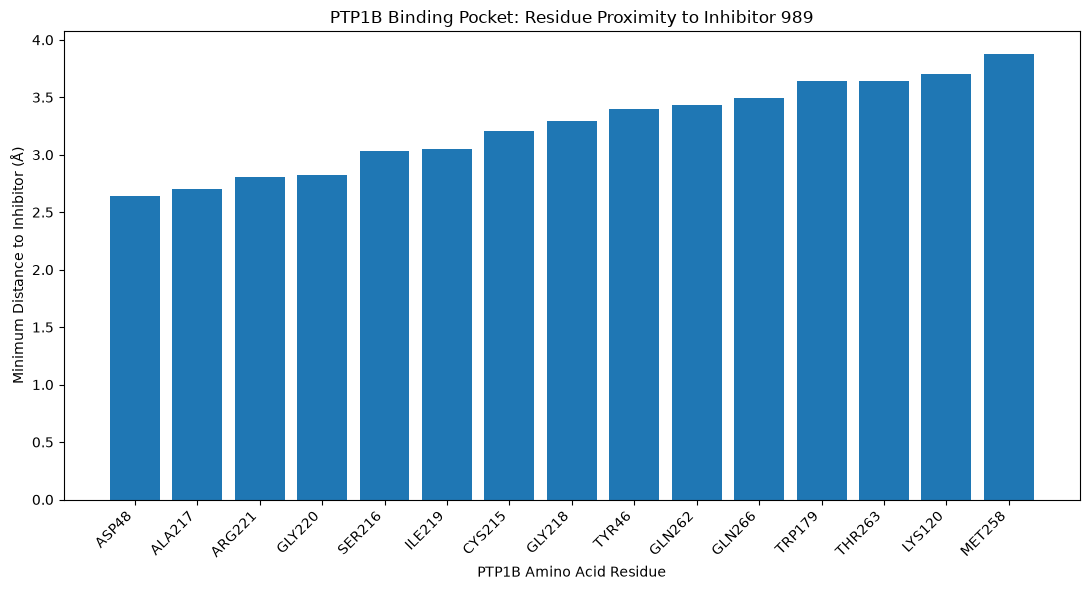

In [13]:
import matplotlib.pyplot as plt

# Create labels for each amino acid
binding_df["Residue_Label"] = (
    binding_df["Residue"]
    + binding_df["Position"].astype(str)
)

# Create figure
plt.figure(figsize=(11, 6))

plt.bar(
    binding_df["Residue_Label"],
    binding_df["Min_Distance_A"]
)

plt.xlabel("PTP1B Amino Acid Residue")
plt.ylabel("Minimum Distance to Inhibitor (Å)")
plt.title("PTP1B Binding Pocket: Residue Proximity to Inhibitor 989")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save figure
plt.savefig(
    project_dir / "figures" / "PTP1B_binding_residues.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
import requests

# Download chemical structure of inhibitor 989
ligand_id = "989"

url = f"https://files.rcsb.org/ligands/download/{ligand_id}_ideal.sdf"

response = requests.get(url, timeout=30)
response.raise_for_status()

# Save SDF file
sdf_path = data_dir / "PTP1B_inhibitor_989_ideal.sdf"
sdf_path.write_bytes(response.content)

print("Inhibitor SDF downloaded successfully!")
print("Saved to:", sdf_path)

Inhibitor SDF downloaded successfully!
Saved to: /Users/tavimangoma/PCOS_Drug_Repurposing/data/PTP1B_inhibitor_989_ideal.sdf


In [15]:
# Read the downloaded SDF file
with open(sdf_path, "r") as f:
    sdf_lines = f.readlines()

print("SDF file contains", len(sdf_lines), "lines")

# Display the first 10 lines
for line in sdf_lines[:10]:
    print(line.rstrip())

SDF file contains 148 lines
989
  CCTOOLS-0919241037

 70 72  0  0  1  0  0  0  0  0999 V2000
    2.6150    3.0260   -4.3440 O   0  0  0  0  0
    1.9200    2.1400   -3.6080 C   0  0  0  0  0
    1.7510    2.3360   -2.4230 O   0  0  0  0  0
    1.3570    0.9160   -4.2490 C   0  0  0  0  0
    1.5260    0.7200   -5.4350 O   0  0  0  0  0
    0.6610    0.0280   -3.5120 N   0  0  0  0  0


In [16]:
from rdkit import Chem
from rdkit.Chem import Descriptors

# Load inhibitor SDF
supplier = Chem.SDMolSupplier(
    str(sdf_path),
    removeHs=False
)

mol = supplier[0]

if mol is not None:
    print("Inhibitor successfully loaded!")
    print("Number of atoms:", mol.GetNumAtoms())
    print("Molecular weight:", round(Descriptors.MolWt(mol), 2))
    print("Molecular formula:", Chem.rdMolDescriptors.CalcMolFormula(mol))
else:
    print("Error loading inhibitor.")

Inhibitor successfully loaded!
Number of atoms: 70
Molecular weight: 533.58
Molecular formula: C29H31N3O7


[22:20:55] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


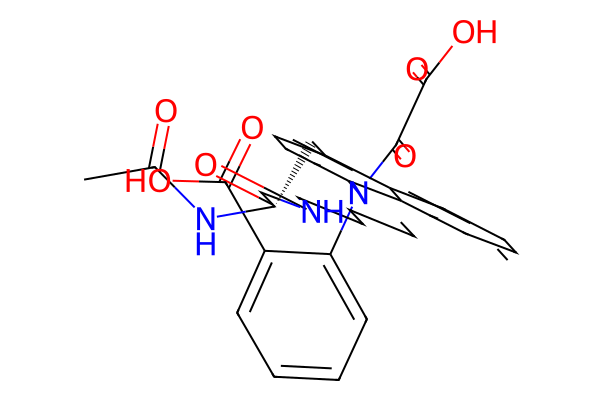

In [17]:
from rdkit.Chem import Draw

# Remove explicit hydrogen atoms for clearer visualization
mol_2d = Chem.RemoveHs(mol)

# Generate 2D molecular image
img = Draw.MolToImage(
    mol_2d,
    size=(600, 400)
)

display(img)

In [18]:
# Save inhibitor molecular structure
output_path = project_dir / "figures" / "inhibitor_989_structure.png"

img.save(output_path)

print("Molecular structure image saved!")
print(output_path)

Molecular structure image saved!
/Users/tavimangoma/PCOS_Drug_Repurposing/figures/inhibitor_989_structure.png


In [19]:
from rdkit import Chem
import numpy as np

# Get the inhibitor's 3D coordinates
conformer = mol.GetConformer()
coordinates = np.array(conformer.GetPositions())

print("Number of conformers:", mol.GetNumConformers())
print("Is 3D:", conformer.Is3D())

print("\nFirst 5 atomic coordinates:")
print(coordinates[:5])

print("\nCoordinate ranges:")
print("X:", np.round(coordinates[:, 0].min(), 2),
      "to", np.round(coordinates[:, 0].max(), 2))
print("Y:", np.round(coordinates[:, 1].min(), 2),
      "to", np.round(coordinates[:, 1].max(), 2))
print("Z:", np.round(coordinates[:, 2].min(), 2),
      "to", np.round(coordinates[:, 2].max(), 2))

Number of conformers: 1
Is 3D: True

First 5 atomic coordinates:
[[ 2.615  3.026 -4.344]
 [ 1.92   2.14  -3.608]
 [ 1.751  2.336 -2.423]
 [ 1.357  0.916 -4.249]
 [ 1.526  0.72  -5.435]]

Coordinate ranges:
X: -5.07 to 4.5
Y: -4.39 to 3.82
Z: -5.94 to 11.64


In [20]:
import requests

# Download inhibitor 989 in its experimental binding position
url = (
    "https://models.rcsb.org/v1/1NL9/ligand"
    "?auth_asym_id=A"
    "&auth_seq_id=322"
    "&encoding=sdf"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

# Save the bound inhibitor
bound_ligand_path = data_dir / "PTP1B_inhibitor_989_bound.sdf"
bound_ligand_path.write_bytes(response.content)

print("Bound inhibitor downloaded successfully!")
print("Saved to:", bound_ligand_path)

Bound inhibitor downloaded successfully!
Saved to: /Users/tavimangoma/PCOS_Drug_Repurposing/data/PTP1B_inhibitor_989_bound.sdf


In [21]:
from rdkit import Chem
import numpy as np

# Load the experimentally bound inhibitor
supplier = Chem.SDMolSupplier(
    str(bound_ligand_path),
    removeHs=False
)

bound_mol = supplier[0]

if bound_mol is None:
    raise ValueError("Could not load bound inhibitor.")

# Calculate center of heavy atoms
conf = bound_mol.GetConformer()

coords = np.array([
    list(conf.GetAtomPosition(atom.GetIdx()))
    for atom in bound_mol.GetAtoms()
    if atom.GetAtomicNum() > 1
])

bound_center = coords.mean(axis=0)

print("Bound inhibitor loaded successfully!")
print("Number of atoms:", bound_mol.GetNumAtoms())
print("Experimental ligand center:", np.round(bound_center, 2))

# Compare with Step 7 coordinates
reference_center = np.array([33.68, 28.42, 20.58])

difference = np.linalg.norm(bound_center - reference_center)

print("Difference from previous center:",
      round(difference, 3), "Å")

Bound inhibitor loaded successfully!
Number of atoms: 39
Experimental ligand center: [33.68 28.42 20.58]
Difference from previous center: 0.006 Å


[22:20:56] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


In [22]:
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

# Check experimental ligand
print("Molecular formula:",
      rdMolDescriptors.CalcMolFormula(bound_mol))

print("Total atoms:", bound_mol.GetNumAtoms())

# Count hydrogen atoms
hydrogen_count = sum(
    1 for atom in bound_mol.GetAtoms()
    if atom.GetAtomicNum() == 1
)

print("Explicit hydrogens:", hydrogen_count)
print("Number of bonds:", bound_mol.GetNumBonds())
print("3D structure:", bound_mol.GetConformer().Is3D())

Molecular formula: C29H31N3O7
Total atoms: 39
Explicit hydrogens: 0
Number of bonds: 41
3D structure: True


In [23]:
# Create a folder for docking files

docking_dir = project_dir / "docking"
docking_dir.mkdir(exist_ok=True)

print("Docking directory created!")
print(docking_dir)

Docking directory created!
/Users/tavimangoma/PCOS_Drug_Repurposing/docking


In [24]:
from Bio.PDB import PDBParser, is_aa

# Load the clean protein
parser = PDBParser(QUIET=True)
protein = parser.get_structure("PTP1B", str(protein_path))

# Examine protein residues
protein_residues = [
    residue
    for residue in protein.get_residues()
    if is_aa(residue, standard=True)
]

print("Protein residues:", len(protein_residues))

# Check for missing backbone atoms
required_atoms = {"N", "CA", "C", "O"}
missing_backbone = []

for residue in protein_residues:
    present_atoms = {
        atom.name for atom in residue.get_atoms()
    }

    missing = required_atoms - present_atoms

    if missing:
        missing_backbone.append({
            "Residue": residue.resname,
            "Position": residue.id[1],
            "Missing": sorted(missing)
        })

print("Residues with missing backbone atoms:",
      len(missing_backbone))

for item in missing_backbone:
    print(item)

Protein residues: 283
Residues with missing backbone atoms: 1
{'Residue': 'ASP', 'Position': 284, 'Missing': ['C', 'CA', 'O']}


In [25]:
# Examine the incomplete residue

chain = protein[0]["A"]

asp284 = chain[284]

print("Residue:", asp284.resname)
print("Position:", asp284.id[1])

print("\nAtoms present:")
for atom in asp284:
    print(atom.name)

Residue: ASP
Position: 284

Atoms present:
N


In [26]:
import numpy as np
from scipy.spatial.distance import cdist

# Get coordinates of ASP284
asp_coords = np.array([
    atom.coord for atom in asp284.get_atoms()
])

# Get inhibitor coordinates
inhibitor_coords = np.array([
    atom.coord for atom in ligand.get_atoms()
    if atom.element != "H"
])

# Calculate minimum distance
distances = cdist(asp_coords, inhibitor_coords)

minimum_distance = distances.min()

print(
    "Minimum distance between ASP284 and inhibitor:",
    round(float(minimum_distance), 2),
    "Å"
)

Minimum distance between ASP284 and inhibitor: 28.93 Å


In [27]:
from Bio.PDB import PDBParser, PDBIO

# Load a fresh copy of the clean protein
parser = PDBParser(QUIET=True)

prepared_protein = parser.get_structure(
    "PTP1B_prepared",
    str(protein_path)
)

# Select chain A
chain = prepared_protein[0]["A"]

# Remove incomplete terminal residue ASP284
chain.detach_child((" ", 284, " "))

# Save corrected protein
io = PDBIO()
io.set_structure(prepared_protein)

repaired_path = docking_dir / "PTP1B_no_ASP284.pdb"
io.save(str(repaired_path))

print("Incomplete ASP284 removed successfully!")
print("Saved to:", repaired_path)

Incomplete ASP284 removed successfully!
Saved to: /Users/tavimangoma/PCOS_Drug_Repurposing/docking/PTP1B_no_ASP284.pdb


In [28]:
# Load the corrected protein
repaired_protein = parser.get_structure(
    "PTP1B_repaired",
    str(repaired_path)
)

# Count residues
residues = list(repaired_protein.get_residues())

print("Number of residues:", len(residues))

# Check remaining missing backbone atoms
required_atoms = {"N", "CA", "C", "O"}
incomplete_residues = []

for residue in residues:
    present = {atom.name for atom in residue}
    missing = required_atoms - present

    if missing:
        incomplete_residues.append(
            (residue.resname, residue.id[1], sorted(missing))
        )

print("Incomplete backbone residues:", incomplete_residues)
print("File exists:", repaired_path.exists())

Number of residues: 282
Incomplete backbone residues: []
File exists: True


In [29]:
from vina import Vina

# Initialize AutoDock Vina
v = Vina(sf_name="vina")

# Load the prepared PTP1B receptor
v.set_receptor(
    str(docking_dir / "PTP1B_receptor.pdbqt")
)

print("PTP1B receptor loaded successfully!")

PTP1B receptor loaded successfully!


In [30]:
# Define the docking search space
center = [33.68, 28.42, 20.58]

# Initial search box dimensions in Angstroms
box_size = [24, 24, 24]

v.compute_vina_maps(
    center=center,
    box_size=box_size
)

print("Docking box created successfully!")
print("Center:", center)
print("Box dimensions:", box_size)

Computing Vina grid ... done.
Docking box created successfully!
Center: [33.68, 28.42, 20.58]
Box dimensions: [24, 24, 24]


In [31]:
from rdkit import Chem

# Use the experimentally bound inhibitor
ligand_mol = Chem.Mol(bound_mol)

# Check chemical bond information
print("Original atoms:", ligand_mol.GetNumAtoms())
print("Original bonds:", ligand_mol.GetNumBonds())

if ligand_mol.GetNumBonds() == 0:
    raise ValueError("Ligand has no bond information.")

# Add explicit hydrogen atoms while preserving
# the original heavy-atom coordinates
ligand_with_h = Chem.AddHs(
    ligand_mol,
    addCoords=True
)

print("\nAfter adding hydrogens:")
print("Total atoms:", ligand_with_h.GetNumAtoms())
print("Number of bonds:", ligand_with_h.GetNumBonds())
print("3D structure:", ligand_with_h.GetConformer().Is3D())

Original atoms: 39
Original bonds: 41

After adding hydrogens:
Total atoms: 70
Number of bonds: 72
3D structure: True


In [32]:
# Save ligand with explicit hydrogen atoms
prepared_ligand_path = (
    docking_dir / "inhibitor_989_prepared.sdf"
)

writer = Chem.SDWriter(str(prepared_ligand_path))
writer.write(ligand_with_h)
writer.close()

print("Prepared ligand saved successfully!")
print("File:", prepared_ligand_path)

Prepared ligand saved successfully!
File: /Users/tavimangoma/PCOS_Drug_Repurposing/docking/inhibitor_989_prepared.sdf


Redocking Validation

In [33]:
from vina import Vina

# Initialize docking
v = Vina(sf_name="vina", cpu=4, seed=42)

# Load prepared receptor
v.set_receptor(
    str(docking_dir / "PTP1B_receptor.pdbqt")
)

# Load prepared inhibitor
v.set_ligand_from_file(
    str(docking_dir / "inhibitor_989.pdbqt")
)

# Set docking search space
v.compute_vina_maps(
    center=[33.68, 28.42, 20.58],
    box_size=[24, 24, 24]
)

print("Starting molecular docking...")

# Run docking
v.dock(exhaustiveness=16, n_poses=10)

# Save predicted binding poses
output_path = docking_dir / "inhibitor_989_docked.pdbqt"

v.write_poses(
    str(output_path),
    n_poses=10,
    overwrite=True
)

print("Molecular docking completed!")
print("Results saved to:", output_path)

Computing Vina grid ... done.
Starting molecular docking...
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.478          0          0
   2       -7.279      1.467      2.522
   3       -7.133      3.437      6.257
   4       -7.121      2.597      5.223
   5       -7.107      2.428      5.161
   6       -7.099      1.317       1.98
   7       -7.083      1.991      7.965
   8       -7.078      2.032       3.28
   9       -6.834       1.67      3.055
  10       -6.798      2.249      4.273
Molecular docking completed!
Results saved to: /Users/tavimangoma/PCOS_Drug_Repurposing/docking/inhibitor_989_docked.pdbqt


In [34]:
import pandas as pd

# Retrieve predicted binding energies
energies = v.energies()

# Create results table
docking_results = pd.DataFrame({
    "Pose": range(1, len(energies) + 1),
    "Binding_Energy_kcal_mol": energies[:, 0]
})

display(docking_results)

# Save results
results_file = results_dir / "inhibitor_989_docking_scores.csv"
docking_results.to_csv(results_file, index=False)

print("Docking scores saved!")

,Pose,Binding_Energy_kcal_mol
0,1,-7.478
1,2,-7.279
2,3,-7.133
3,4,-7.121
4,5,-7.107
5,6,-7.099
6,7,-7.083
7,8,-7.078
8,9,-6.834


Docking scores saved!


In [35]:
from rdkit import Chem

docked_sdf = docking_dir / "inhibitor_989_docked.sdf"

supplier = Chem.SDMolSupplier(
    str(docked_sdf),
    removeHs=False
)

docked_molecules = [
    mol for mol in supplier if mol is not None
]

print("Number of docking poses:", len(docked_molecules))
print("Reference atoms:", bound_mol.GetNumAtoms())
print("Docked pose atoms:", docked_molecules[0].GetNumAtoms())

Number of docking poses: 10
Reference atoms: 39
Docked pose atoms: 70


In [36]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMolAlign

# Remove hydrogens from both structures
reference = Chem.RemoveHs(bound_mol)

# Calculate RMSD without repositioning either structure
rmsd_results = []

for i, docked in enumerate(docked_molecules, start=1):
    predicted = Chem.RemoveHs(docked)

    try:
        rmsd = rdMolAlign.CalcRMS(
            predicted,
            reference
        )

        rmsd_results.append({
            "Pose": i,
            "RMSD_A": round(float(rmsd), 3)
        })

    except Exception as e:
        print(f"Pose {i} could not be compared: {e}")

rmsd_df = pd.DataFrame(rmsd_results)

display(rmsd_df)

,Pose,RMSD_A
0,1,6.468
1,2,6.294
2,3,1.193
3,4,3.847
4,5,3.111
5,6,6.278
6,7,8.868
7,8,5.857
8,9,6.122
9,10,4.979


In [37]:
from rdkit import Chem

reference = Chem.RemoveHs(bound_mol)
predicted = Chem.RemoveHs(docked_molecules[0])

print("Reference heavy atoms:", reference.GetNumAtoms())
print("Predicted heavy atoms:", predicted.GetNumAtoms())

print("Reference bonds:", reference.GetNumBonds())
print("Predicted bonds:", predicted.GetNumBonds())

print("Reference SMILES:", Chem.MolToSmiles(reference))
print("Predicted SMILES:", Chem.MolToSmiles(predicted))

same_structure = (
    Chem.MolToSmiles(reference)
    == Chem.MolToSmiles(predicted)
)

print("Matching chemical structures:", same_structure)

Reference heavy atoms: 39
Predicted heavy atoms: 39
Reference bonds: 41
Predicted bonds: 41
Reference SMILES: CCCCCNC(=O)[C@H](Cc1ccc(N(C(=O)C(=O)O)c2ccccc2C(=O)O)c2ccccc12)NC(C)=O
Predicted SMILES: CCCCCNC(=O)[C@H](Cc1ccc(N(C(=O)C(=O)O)c2ccccc2C(=O)O)c2ccccc12)NC(C)=O
Matching chemical structures: True


In [38]:
# Combine docking scores and RMSD values
validation_df = pd.merge(
    docking_results,
    rmsd_df,
    on="Pose"
)

# Identify poses below the 2 Å benchmark
validation_df["RMSD_below_2A"] = (
    validation_df["RMSD_A"] < 2.0
)

display(validation_df)

# Save your validation results
validation_path = (
    results_dir / "PTP1B_redocking_validation.csv"
)

validation_df.to_csv(validation_path, index=False)

print("Validation results saved!")

,Pose,Binding_Energy_kcal_mol,RMSD_A,RMSD_below_2A
0,1,-7.478,6.468,False
1,2,-7.279,6.294,False
2,3,-7.133,1.193,True
3,4,-7.121,3.847,False
4,5,-7.107,3.111,False
5,6,-7.099,6.278,False
6,7,-7.083,8.868,False
7,8,-7.078,5.857,False
8,9,-6.834,6.122,False


Validation results saved!


In [39]:
from vina import Vina

# Initialize a new docking experiment
v2 = Vina(sf_name="vina", cpu=4, seed=42)

# Load prepared protein and inhibitor
v2.set_receptor(
    str(docking_dir / "PTP1B_receptor.pdbqt")
)

v2.set_ligand_from_file(
    str(docking_dir / "inhibitor_989.pdbqt")
)

# Use the same docking box
v2.compute_vina_maps(
    center=[33.68, 28.42, 20.58],
    box_size=[24, 24, 24]
)

# Increase search thoroughness
v2.dock(
    exhaustiveness=32,
    n_poses=10
)

# Save results under a new filename
v2.write_poses(
    str(docking_dir / "inhibitor_989_docked_ex32.pdbqt"),
    n_poses=10,
    overwrite=True
)

print("Improved docking experiment completed!")

Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.435          0          0
   2       -7.226      1.484      2.485
   3       -7.194      1.189      2.011
   4       -7.186      1.959      3.449
   5        -7.08      3.415      6.163
   6       -7.067      2.587      5.174
   7       -7.054      2.407      5.106
   8       -7.036      1.977       7.94
   9       -6.752      2.777      5.341
  10       -6.744      2.202      4.224
Improved docking experiment completed!


In [40]:
# Retrieve new docking results
energies_32 = v2.energies()

new_results = pd.DataFrame({
    "Pose": range(1, len(energies_32) + 1),
    "Binding_Energy_kcal_mol": energies_32[:, 0]
})

display(new_results)

,Pose,Binding_Energy_kcal_mol
0,1,-7.435
1,2,-7.226
2,3,-7.194
3,4,-7.186
4,5,-7.080
5,6,-7.067
6,7,-7.054
7,8,-7.036
8,9,-6.752


In [41]:
from rdkit import Chem

# Load new docking poses
new_sdf = docking_dir / "inhibitor_989_docked_ex32.sdf"

supplier = Chem.SDMolSupplier(
    str(new_sdf),
    removeHs=False
)

new_docked_molecules = [
    mol for mol in supplier if mol is not None
]

print("Number of new docking poses:", len(new_docked_molecules))

Number of new docking poses: 10


In [42]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMolAlign

# Experimental reference ligand
reference = Chem.RemoveHs(bound_mol)

rmsd_32 = []

for i, docked in enumerate(new_docked_molecules, start=1):

    predicted = Chem.RemoveHs(docked)

    # Confirm chemical structures match
    if Chem.MolToSmiles(predicted) != Chem.MolToSmiles(reference):
        raise ValueError(
            f"Chemical structure mismatch for pose {i}"
        )

    # Calculate RMSD without structural alignment
    rmsd = rdMolAlign.CalcRMS(
        predicted,
        reference
    )

    rmsd_32.append({
        "Pose": i,
        "RMSD_A": round(float(rmsd), 3)
    })

rmsd_32_df = pd.DataFrame(rmsd_32)

# Combine docking scores with RMSD results
validation_32 = pd.merge(
    new_results,
    rmsd_32_df,
    on="Pose",
    validate="one_to_one"
)

validation_32["RMSD_below_2A"] = (
    validation_32["RMSD_A"] < 2.0
)

display(validation_32)

,Pose,Binding_Energy_kcal_mol,RMSD_A,RMSD_below_2A
0,1,-7.435,6.382,False
1,2,-7.226,6.294,False
2,3,-7.194,6.554,False
3,4,-7.186,5.539,False
4,5,-7.080,1.193,True
5,6,-7.067,3.847,False
6,7,-7.054,3.111,False
7,8,-7.036,8.797,False
8,9,-6.752,4.691,False


In [43]:
validation_32.to_csv(
    results_dir / "PTP1B_validation_ex32.csv",
    index=False
)

print("Second docking validation saved!")

Second docking validation saved!


In [45]:
figures_dir = project_dir / "figures"
figures_dir.mkdir(exist_ok=True)

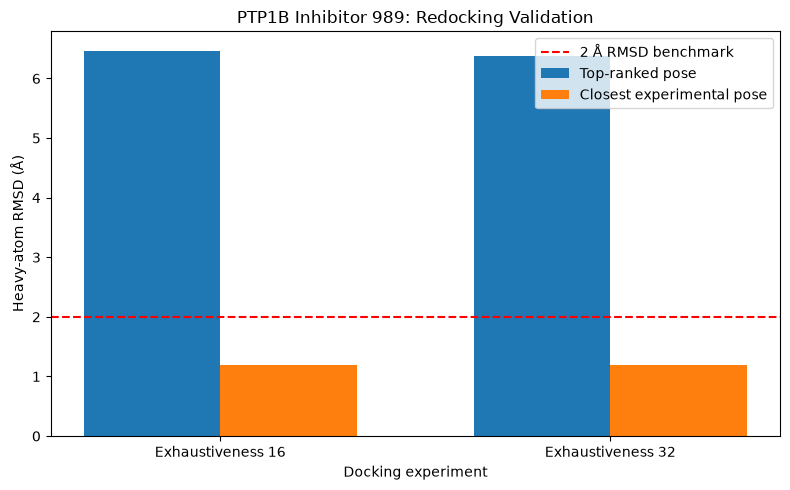

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your redocking experiments
experiments = ["Exhaustiveness 16", "Exhaustiveness 32"]

top_pose_rmsd = [6.468, 6.382]
lowest_rmsd = [1.193, 1.193]

x = np.arange(len(experiments))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width/2,
    top_pose_rmsd,
    width,
    label="Top-ranked pose"
)

ax.bar(
    x + width/2,
    lowest_rmsd,
    width,
    label="Closest experimental pose"
)

ax.axhline(
    y=2.0,
    color="red",
    linestyle="--",
    label="2 Å RMSD benchmark"
)

ax.set_ylabel("Heavy-atom RMSD (Å)")
ax.set_xlabel("Docking experiment")
ax.set_title("PTP1B Inhibitor 989: Redocking Validation")

ax.set_xticks(x)
ax.set_xticklabels(experiments)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "PTP1B_redocking_comparison.png",
    dpi=300
)

plt.show()